# 01 — Exploratory Data Analysis (EDA) | Telecom Customer Churn

**Mục tiêu:** khảo sát sự khác biệt giữa khách hàng churn / không churn, tìm giả thuyết có thể kiểm định, nhận diện đặc trưng khó xử lý, và chuẩn bị quy trình thực nghiệm chung cho 4 mô hình.

**Dữ liệu:** `Telecom Data.csv` (51.047 dòng, có nhãn) và `Telecom - Prediction Data.csv` (20.000 dòng, không có nhãn). Không chỉnh sửa CSV gốc.

**Lưu ý phương pháp:** EDA trên toàn bộ tập có nhãn trong notebook này là **khám phá mô tả**, không dùng để quyết định feature selection/hyperparameters rồi báo cáo test score như một đánh giá độc lập. Trước khi train, cần cố định test set; mọi quyết định học từ dữ liệu (imputation, scaling, encoding, feature selection, resampling) chỉ fit trên training folds. Phân tích target-guided dùng để chọn đặc trưng nên được lặp lại trên train-only.

## 1. Thiết lập và tải dữ liệu

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next((q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'data/raw/Telecom Data.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục project hoặc notebooks/; thiếu data/raw/Telecom Data.csv')
sys.path.insert(0, str(ROOT))
TARGET = 'Churn'
ID = 'CustomerID'
REVIEW_FOR_LEAKAGE = ['RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']

FIG = ROOT / 'results/figures'
FIG.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(ROOT / 'data/raw/Telecom Data.csv')
predict = pd.read_csv(ROOT / 'data/raw/Telecom - Prediction Data.csv')
assert train[TARGET].isin(['Yes','No']).all()
assert predict[TARGET].isna().all()
train['ChurnFlag'] = train[TARGET].eq('Yes').astype(int)
sns.set_theme(style='whitegrid', palette='deep')
print('Train:', train.shape, '| Unlabeled:', predict.shape)
display(train.head(3))

Train: (51047, 59) | Unlabeled: (20000, 58)


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus,ChurnFlag
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,4,No,0,30,Yes,1-Highest,Suburban,Professional,No,1
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,5,No,0,30,No,4-Medium,Suburban,Professional,Yes,1
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes,0


## 2. Phân bố biến mục tiêu và baseline ngây thơ

,count,percent
Churn,,
No,36336,71.18
Yes,14711,28.82


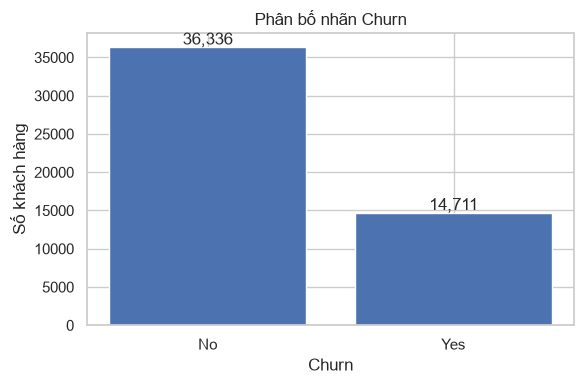

Majority-class baseline accuracy: 71.18%


In [2]:
counts = train[TARGET].value_counts().reindex(['No','Yes'])
summary = pd.DataFrame({'count': counts, 'percent': (counts / len(train)*100).round(2)})
display(summary)
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(counts.index, counts.values)
ax.set(xlabel='Churn', ylabel='Số khách hàng', title='Phân bố nhãn Churn')
for i,v in enumerate(counts.values): ax.text(i, v+350, f'{v:,}', ha='center')
fig.tight_layout(); fig.savefig(FIG/'eda_01_target_distribution.png', dpi=160); plt.show()
print(f"Majority-class baseline accuracy: {counts.max()/len(train):.2%}")

**Cách diễn giải:** tỷ lệ lớp dương cho biết mức mất cân bằng. Accuracy của bộ phân loại luôn đoán `No` là mốc tham chiếu, **không** phản ánh khả năng phát hiện churn. Trong thực nghiệm cần xem thêm Precision, Recall, F1, ROC-AUC và PR-AUC.

## 3. Phân loại kiểu dữ liệu, missingness và cardinality

Numerical: 34 | Categorical: 22


,dtype,missing_n,missing_pct,unique_n
AgeHH1,float64,909,1.78,43
AgeHH2,float64,909,1.78,43
PercChangeRevenues,float64,367,0.72,2899
PercChangeMinutes,float64,367,0.72,2262
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719
OverageMinutes,float64,156,0.31,746
RoamingCalls,float64,156,0.31,530
TotalRecurringCharge,float64,156,0.31,214
DirectorAssistedCalls,float64,156,0.31,146


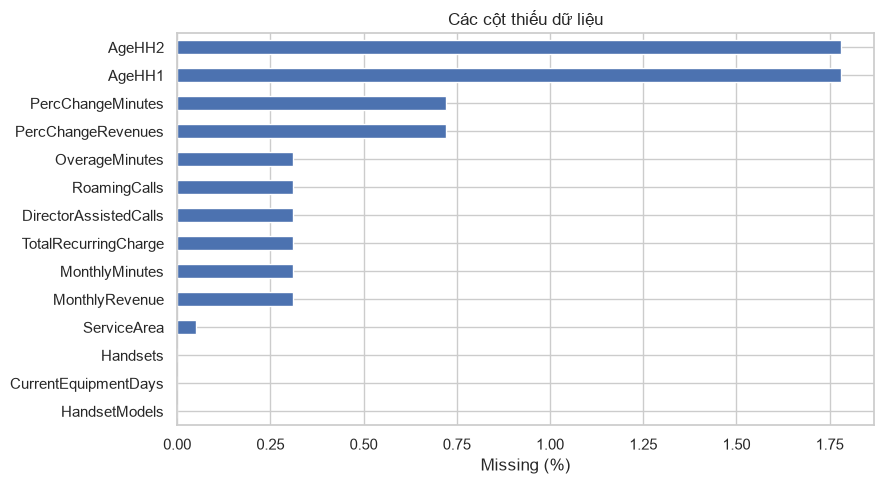

Giá trị Unknown ở HandsetPrice: 28982


In [3]:
features = train.drop(columns=[ID, TARGET, 'ChurnFlag'], errors='ignore')
num_cols = features.select_dtypes(include='number').columns.tolist()
cat_cols = features.select_dtypes(exclude='number').columns.tolist()
print(f'Numerical: {len(num_cols)} | Categorical: {len(cat_cols)}')
quality = pd.DataFrame({'dtype': features.dtypes.astype(str),
                        'missing_n': features.isna().sum(),
                        'missing_pct': features.isna().mean().mul(100).round(2),
                        'unique_n': features.nunique(dropna=True)})
display(quality.sort_values(['missing_pct','unique_n'], ascending=False).head(25))
fig, ax = plt.subplots(figsize=(9,5))
miss = quality.loc[quality.missing_n.gt(0), 'missing_pct'].sort_values().tail(20)
if len(miss):
    miss.plot.barh(ax=ax); ax.set(xlabel='Missing (%)', title='Các cột thiếu dữ liệu')
else: ax.text(.5,.5,'Không có missing NaN',ha='center')
fig.tight_layout(); fig.savefig(FIG/'eda_02_missingness.png', dpi=160); plt.show()
print('Giá trị Unknown ở HandsetPrice:', int(train['HandsetPrice'].astype('string').str.strip().eq('Unknown').sum()))

**Chú ý:** chuỗi `Unknown` có thể là missing được mã hóa dưới dạng text. `ServiceArea` có nhiều mức; One-Hot Encoding có thể tạo rất nhiều cột. Không tự động xóa cột chỉ vì nhiều mức; thử nghiệm lựa chọn encoding trong training pipeline.

## 4. Các đặc trưng số: phân phối và so sánh theo Churn

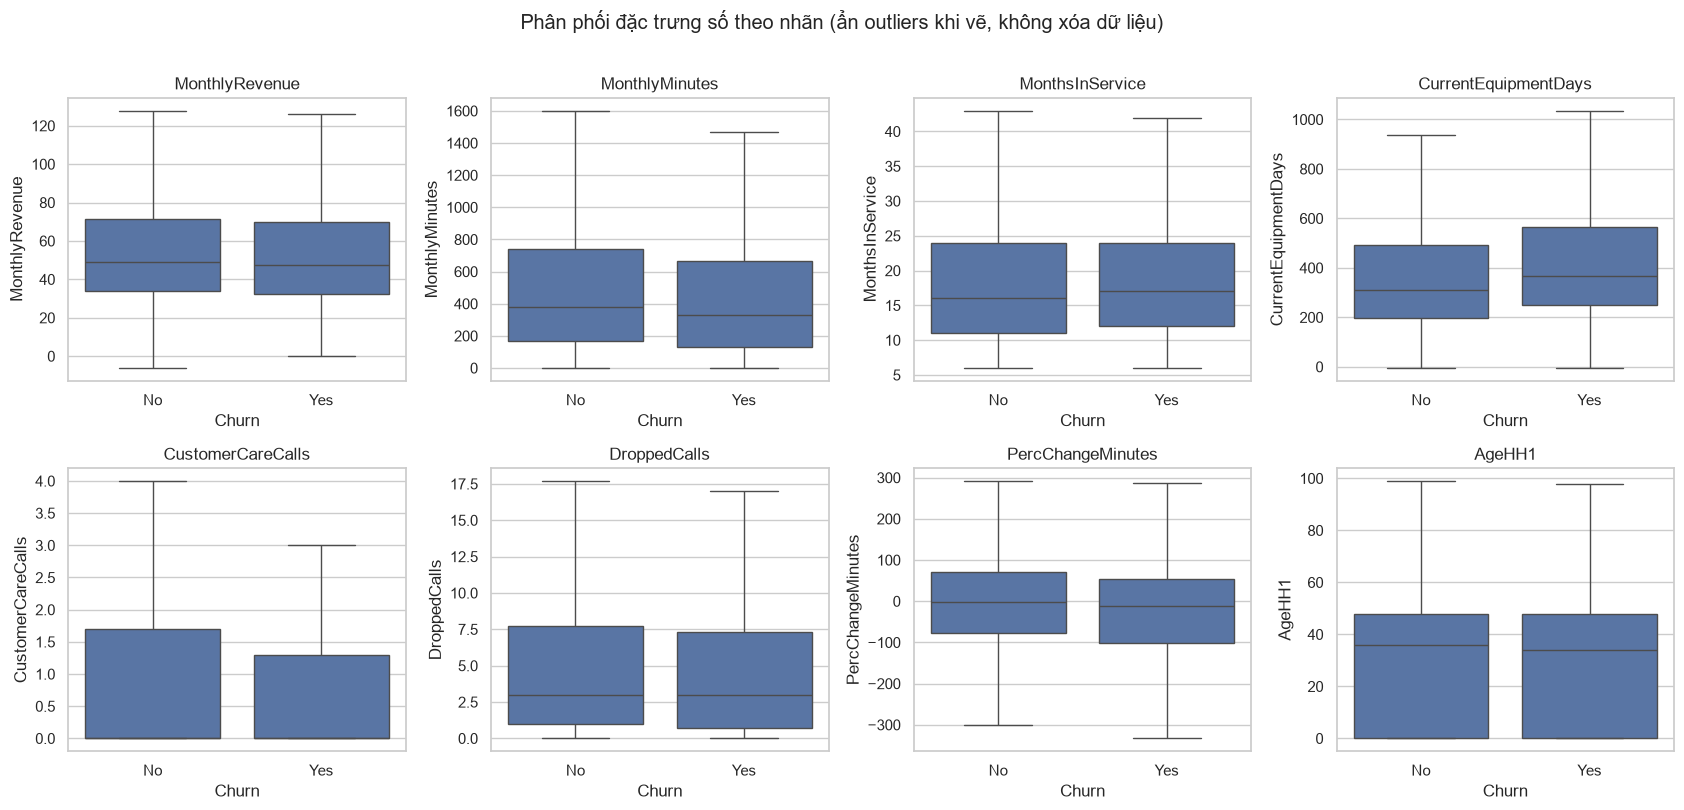

MonthlyRevenue        MonthlyMinutes         MonthsInService         \
              median   mean         median    mean          median   mean   
Churn                                                                       
No             48.82  59.17          381.0  542.55            16.0  18.64   
Yes            47.52  58.00          330.0  483.83            17.0  19.04   

      CurrentEquipmentDays        CustomerCareCalls       DroppedCalls        \
                    median   mean            median  mean       median  mean   
Churn                                                                          
No                   310.0  363.8               0.0  1.98          3.0  6.10   
Yes                  366.0  421.9               0.0  1.58          3.0  5.79   

      PercChangeMinutes        AgeHH1         
                 median   mean median   mean  
Churn                                         
No                 -3.0  -5.97   36.0  31.76  
Yes               -11.0 -25.46   34.0  30.31

In [4]:
selected_num = [c for c in ['MonthlyRevenue','MonthlyMinutes','MonthsInService','CurrentEquipmentDays','CustomerCareCalls','DroppedCalls','PercChangeMinutes','AgeHH1'] if c in num_cols]
fig, axes = plt.subplots(2,4, figsize=(17,8))
for ax, col in zip(axes.flat, selected_num):
    sns.boxplot(data=train, x=TARGET, y=col, order=['No','Yes'], ax=ax, showfliers=False)
    ax.set_title(col)
for ax in axes.flat[len(selected_num):]: ax.axis('off')
fig.suptitle('Phân phối đặc trưng số theo nhãn (ẩn outliers khi vẽ, không xóa dữ liệu)', y=1.01)
fig.tight_layout(); fig.savefig(FIG/'eda_03_numeric_by_churn.png', dpi=160); plt.show()
agg = train.groupby(TARGET)[selected_num].agg(['median','mean']).round(2)
display(agg)

**Giải thích:** boxplot mô tả phân bố, không chứng minh quan hệ nhân quả. Trung bình có thể bị ảnh hưởng bởi outlier; đối chiếu thêm median. Không dùng trực tiếp chênh lệch trung bình để kết luận mô hình nào sẽ dự đoán tốt hơn.

## 5. Tương quan số và liên hệ đơn biến với Churn

,pearson_r_with_churn
CurrentEquipmentDays,0.103688
RetentionCalls,0.065301
TotalRecurringCharge,-0.061296
MonthlyMinutes,-0.050166
OffPeakCallsInOut,-0.040784
HandsetModels,-0.040048
PeakCallsInOut,-0.040029
ReceivedCalls,-0.037453
CustomerCareCalls,-0.035510
RetentionOffersAccepted,0.034953


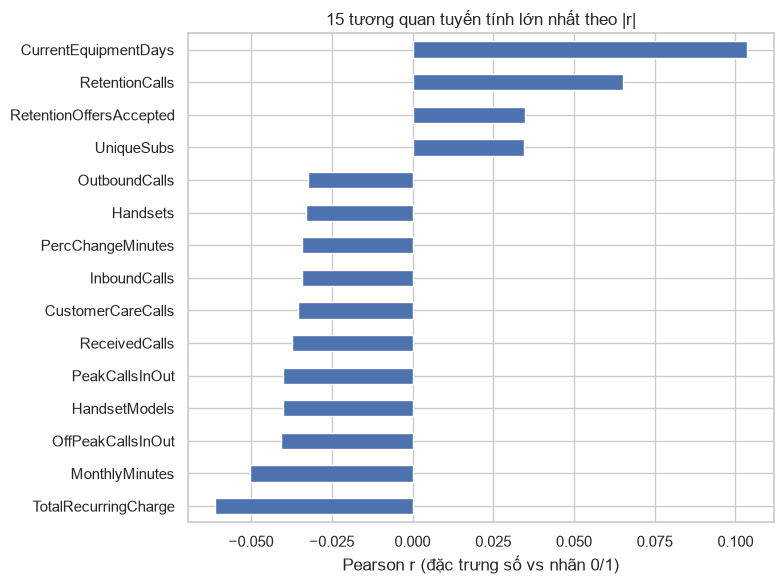

Cặp feature-feature có |r| cao nhất (tham khảo):


,feature_a,feature_b,abs_r
841,Handsets,HandsetModels,0.887838
47,MonthlyMinutes,ReceivedCalls,0.828902
324,BlockedCalls,DroppedBlockedCalls,0.816328
4,MonthlyRevenue,OverageMinutes,0.787834
771,UniqueSubs,ActiveSubs,0.775776
50,MonthlyMinutes,PeakCallsInOut,0.772396
51,MonthlyMinutes,OffPeakCallsInOut,0.764978
458,ReceivedCalls,PeakCallsInOut,0.746892
493,OutboundCalls,OffPeakCallsInOut,0.742311
459,ReceivedCalls,OffPeakCallsInOut,0.738185


In [5]:
corr = train[num_cols + ['ChurnFlag']].corr(numeric_only=True)
assoc = corr['ChurnFlag'].drop('ChurnFlag').dropna().sort_values(key=lambda s:s.abs(), ascending=False)
display(pd.DataFrame({'pearson_r_with_churn': assoc}).head(20))
fig, ax = plt.subplots(figsize=(8,6))
assoc.head(15).sort_values().plot.barh(ax=ax)
ax.set(xlabel='Pearson r (đặc trưng số vs nhãn 0/1)', title='15 tương quan tuyến tính lớn nhất theo |r|')
fig.tight_layout(); fig.savefig(FIG/'eda_04_numeric_associations.png', dpi=160); plt.show()
print('Cặp feature-feature có |r| cao nhất (tham khảo):')
cm = train[num_cols].corr().abs()
# Loại đường chéo chính mà không sửa trực tiếp NumPy array
cm = cm.mask(np.eye(len(cm), dtype=bool))
pairs = cm.stack().reset_index(); pairs.columns=['feature_a','feature_b','abs_r']
pairs['pair_key'] = pairs.apply(lambda r: tuple(sorted([r.feature_a,r.feature_b])), axis=1)
display(pairs.drop_duplicates('pair_key').nlargest(12,'abs_r').drop(columns='pair_key'))

**Giới hạn:** Pearson r chỉ đo quan hệ tuyến tính. Tương quan thấp không đồng nghĩa đặc trưng vô ích cho Decision Tree / Random Forest / SVM. Cặp đặc trưng tương quan cao gợi ý đa cộng tuyến; có thể kiểm tra regularization và feature selection.

## 6. Các đặc trưng phân loại: tỷ lệ churn theo nhóm


CreditRating | cardinality: 7


,n,churn_rate
CreditRating,,
2-High,18993,30.07
1-Highest,8522,30.84
3-Good,8410,31.01
5-Low,6499,22.10
4-Medium,5357,26.12
7-Lowest,2114,28.95
6-VeryLow,1152,27.43



PrizmCode | cardinality: 4


,n,churn_rate
PrizmCode,,
Other,24655,28.62
Suburban,16378,28.14
Town,7589,29.99
Rural,2425,31.71



Occupation | cardinality: 8


,n,churn_rate
Occupation,,
Other,37637,29.05
Professional,8755,28.18
Crafts,1519,28.04
Clerical,986,29.31
Self,879,27.65
Retired,733,25.24
Student,381,30.97
Homemaker,157,32.48


... (4 outputs left out)


HandsetWebCapable | cardinality: 2


,n,churn_rate
HandsetWebCapable,,
Yes,46046,27.89
No,5001,37.35



ServiceArea | cardinality: 747


,n,churn_rate
ServiceArea,,
NYCBRO917,1684,27.43
HOUHOU281,1510,25.63
DALDAL214,1498,27.44
NYCMAN917,1182,27.66
APCFCH703,783,27.71
DALFTW817,782,27.37
SANSAN210,724,27.90
APCSIL301,670,26.12
SANAUS512,612,27.12


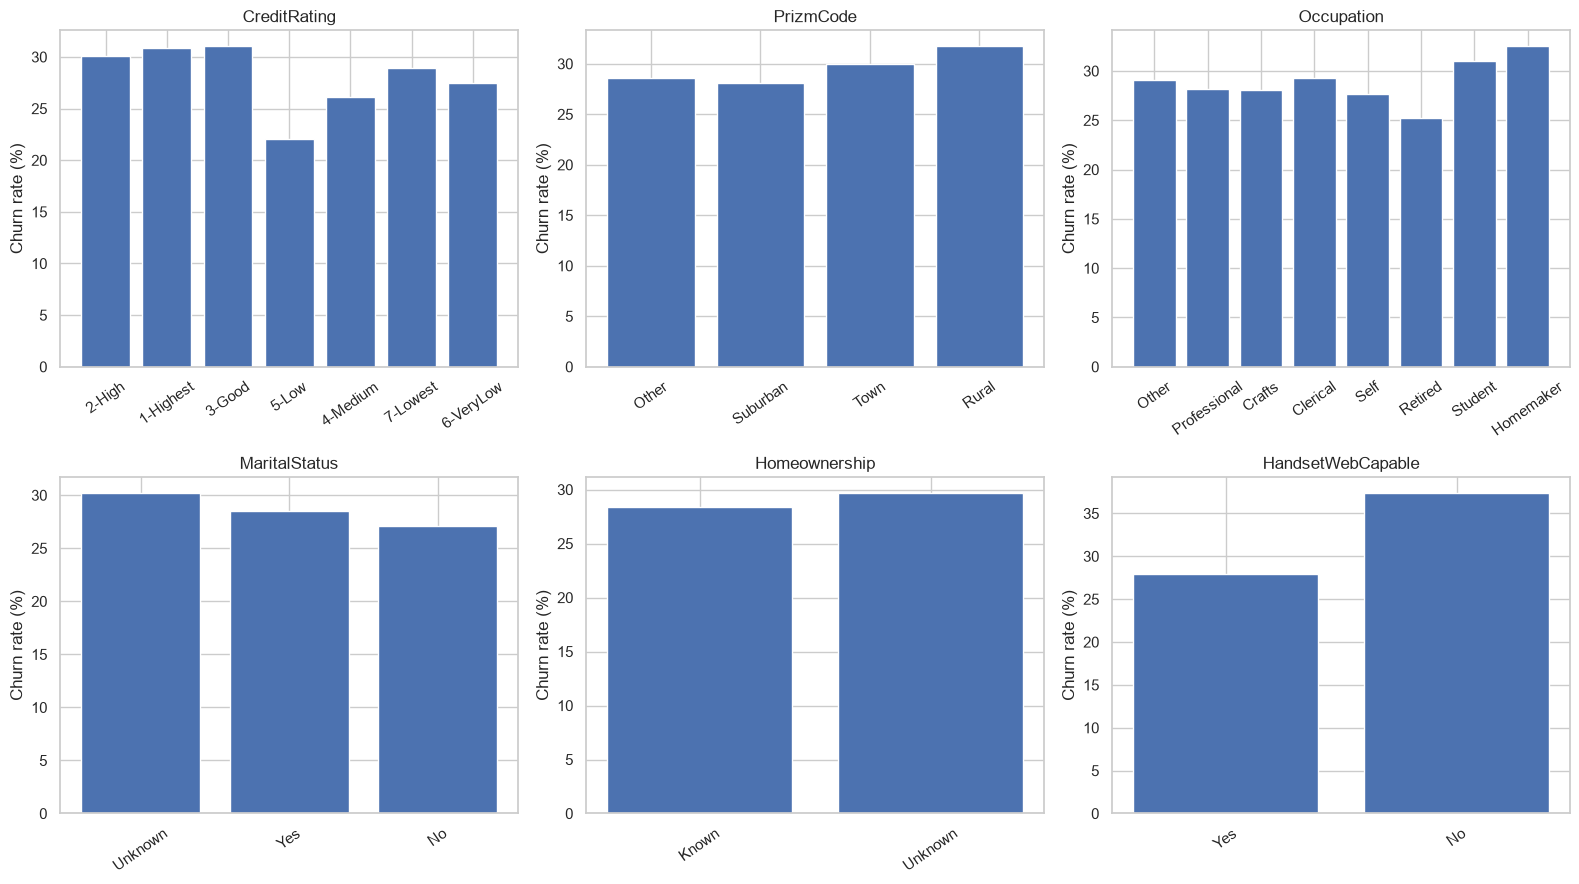

In [6]:
selected_cat = [c for c in ['CreditRating','PrizmCode','Occupation','MaritalStatus','Homeownership','HandsetWebCapable','ServiceArea'] if c in cat_cols]
for col in selected_cat:
    g = train.groupby(col, dropna=False)['ChurnFlag'].agg(['size','mean']).rename(columns={'size':'n','mean':'churn_rate'})
    g['churn_rate'] = (g['churn_rate']*100).round(2)
    print(f'\n{col} | cardinality: {train[col].nunique(dropna=True)}')
    display(g.sort_values('n', ascending=False).head(12))
fig, axes = plt.subplots(2,3, figsize=(16,9))
for ax,col in zip(axes.flat, [c for c in selected_cat if c!='ServiceArea']):
    g = train.groupby(col, dropna=False)['ChurnFlag'].agg(['size','mean'])
    g = g[g['size']>=100].sort_values('size', ascending=False).head(8)
    if len(g):
        ax.bar(g.index.astype(str), g['mean'].mul(100))
        ax.tick_params(axis='x', labelrotation=35); ax.set(ylabel='Churn rate (%)', xlabel='', title=col)
for ax in axes.flat[len([c for c in selected_cat if c!='ServiceArea']):]: ax.axis('off')
fig.tight_layout(); fig.savefig(FIG/'eda_05_categorical_churn_rate.png', dpi=160); plt.show()

**Chú ý:** tỷ lệ churn ở nhóm rất nhỏ có độ bất định cao; chỉ trực quan hóa nhóm có ít nhất 100 quan sát (ngưỡng minh họa). Không suy diễn rằng nghề nghiệp, khu vực hay xếp hạng tín dụng là nguyên nhân gây churn. Với `ServiceArea`, cân nhắc gộp nhóm hiếm hoặc encoding phù hợp, chỉ học ánh xạ trên train.

## 7. Kiểm tra tín hiệu missingness liên quan Churn

In [7]:
rows=[]
for col in features.columns:
    miss = features[col].isna()
    if miss.any() and (~miss).any():
        rows.append({'feature':col, 'missing_n':int(miss.sum()),
                     'churn_missing_pct': round(train.loc[miss,'ChurnFlag'].mean()*100,2),
                     'churn_present_pct': round(train.loc[~miss,'ChurnFlag'].mean()*100,2)})
missing_target = pd.DataFrame(rows)
if not missing_target.empty:
    missing_target['gap_pp'] = (missing_target.churn_missing_pct - missing_target.churn_present_pct).round(2)
    display(missing_target.reindex(missing_target.gap_pp.abs().sort_values(ascending=False).index).head(20))
else: print('Không có cột thiếu NaN')

,feature,missing_n,churn_missing_pct,churn_present_pct,gap_pp
10,HandsetModels,1,0.00,28.82,-28.82
9,Handsets,1,0.00,28.82,-28.82
11,CurrentEquipmentDays,1,0.00,28.82,-28.82
6,PercChangeMinutes,367,56.68,28.62,28.06
7,PercChangeRevenues,367,56.68,28.62,28.06
8,ServiceArea,24,50.00,28.81,21.19
5,RoamingCalls,156,44.87,28.77,16.10
4,OverageMinutes,156,44.87,28.77,16.10
3,DirectorAssistedCalls,156,44.87,28.77,16.10
2,TotalRecurringCharge,156,44.87,28.77,16.10


**Giả thuyết:** missingness có thể chứa tín hiệu. Có thể so sánh `SimpleImputer(add_indicator=True)` với imputation không indicator, nhưng mọi bước phải fit trong cross-validation.

## 8. Kiểm tra train–prediction drift (không dùng nhãn)

,feature,train_median,prediction_median,train_missing_pct,prediction_missing_pct
0,MonthlyRevenue,48.46,48.66,0.31,0.30
1,MonthlyMinutes,366.00,365.00,0.31,0.30
2,MonthsInService,16.00,16.00,0.00,0.00
3,CurrentEquipmentDays,329.00,331.00,0.00,0.00
4,AgeHH1,36.00,36.00,1.78,1.68


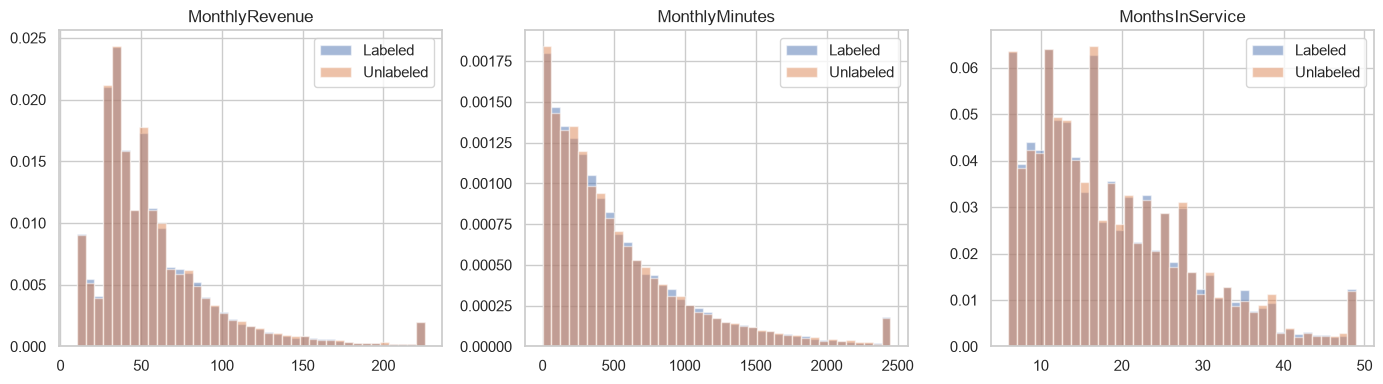

In [8]:
drift_cols = [c for c in ['MonthlyRevenue','MonthlyMinutes','MonthsInService','CurrentEquipmentDays','AgeHH1'] if c in num_cols]
rows=[]
for col in drift_cols:
    a=train[col].dropna(); z=predict[col].dropna()
    rows.append({'feature':col,'train_median':a.median(),'prediction_median':z.median(),
                 'train_missing_pct':train[col].isna().mean()*100,
                 'prediction_missing_pct':predict[col].isna().mean()*100})
display(pd.DataFrame(rows).round(2))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,drift_cols[:3]):
    a=train[col].dropna(); z=predict[col].dropna()
    low,high=np.quantile(pd.concat([a,z]),[.01,.99])
    bins=np.linspace(low,high,40) if low<high else 20
    ax.hist(a.clip(low,high),bins=bins,density=True,alpha=.5,label='Labeled')
    ax.hist(z.clip(low,high),bins=bins,density=True,alpha=.5,label='Unlabeled')
    ax.set_title(col); ax.legend()
fig.tight_layout(); fig.savefig(FIG/'eda_06_train_prediction_shift.png',dpi=160); plt.show()

**Giới hạn:** khác biệt phân phối không khẳng định concept drift, vì chưa biết thời điểm và quy trình lấy mẫu. Không thể tính metrics trên file prediction do không có nhãn. Các phép so sánh ở đây chỉ dùng để nhận diện vấn đề triển khai.

## 9. Data leakage, đạo đức dữ liệu và quyết định preprocessing

In [9]:
leakage_review = pd.DataFrame([
    {'feature':ID, 'action':'Loại khỏi X', 'reason':'Mã định danh không phải thông tin hành vi có thể khái quát'},
    *[{'feature':c,'action':'Loại khỏi baseline; chỉ thử lại nếu xác minh thời điểm',
       'reason':'Có thể phản ánh can thiệp giữ chân khách hàng sau thời điểm cần dự đoán'} for c in REVIEW_FOR_LEAKAGE],
    {'feature':'HandsetPrice','action':'Chuyển Unknown -> NaN; cân nhắc biến số', 'reason':'Chuỗi Unknown xuất hiện nhiều'},
    {'feature':'ServiceArea','action':'Encoding trong pipeline; kiểm tra high-cardinality', 'reason':'Nhiều giá trị phân loại'},
])
display(leakage_review)
print('Features baseline:', len([c for c in features.columns if c not in REVIEW_FOR_LEAKAGE]))

,feature,action,reason
0,CustomerID,Loại khỏi X,Mã định danh không phải thông tin hành vi có t...
1,RetentionCalls,Loại khỏi baseline; chỉ thử lại nếu xác minh t...,Có thể phản ánh can thiệp giữ chân khách hàng ...
2,RetentionOffersAccepted,Loại khỏi baseline; chỉ thử lại nếu xác minh t...,Có thể phản ánh can thiệp giữ chân khách hàng ...
3,MadeCallToRetentionTeam,Loại khỏi baseline; chỉ thử lại nếu xác minh t...,Có thể phản ánh can thiệp giữ chân khách hàng ...
4,HandsetPrice,Chuyển Unknown -> NaN; cân nhắc biến số,Chuỗi Unknown xuất hiện nhiều
5,ServiceArea,Encoding trong pipeline; kiểm tra high-cardina...,Nhiều giá trị phân loại


Features baseline: 53


### Kết luận EDA và các giả thuyết cho thí nghiệm

1. **H1 — Imbalanced classification:** Accuracy đơn lẻ có thể đánh lừa; dùng F1, Recall, PR-AUC, ROC-AUC, confusion matrix.
2. **H2 — Preprocessing:** scaling có thể ảnh hưởng LR/SVM nhiều hơn mô hình cây; cần kiểm chứng.
3. **H3 — High cardinality:** `ServiceArea` có thể làm tăng độ phức tạp và thời gian huấn luyện; so sánh có/không có cột này.
4. **H4 — Missingness:** imputation + missing indicators có thể cải thiện một số mô hình.
5. **H5 — Feature selection:** giảm số đặc trưng có thể cải thiện khả năng tổng quát hóa / thời gian chạy, nhưng cần thử nghiệm.
6. **H6 — Retention leakage:** baseline loại các biến retention; chỉ đưa vào nếu chứng minh chúng tồn tại tại thời điểm dự đoán.

**Đầu ra:** biểu đồ tại `results/figures/eda_*.png`. Notebook tiếp theo: xây dựng train/test split cố định và preprocessing pipeline dùng chung cho 4 thuật toán. **Không** khẳng định quan hệ nhân quả từ EDA.